# Visualizations in Python on Sales Data

**AnalytixLabs Case Study — Completed in Jupyter Notebook**

This notebook solves all 8 questions from the supplied case study using **Pandas, NumPy and Matplotlib**.

The case study asks us to analyze two years of pharmaceutical sales data (2015 and 2016), reshape/aggregate the data where required, and create the requested visualizations. The original case study specifically asks for grouping followed by reshaping with operations such as `groupby()`, `stack()`, `unstack()` and `pivot()`.


## Case-study requirements

1. Compare Sales by Region for 2016 with 2015 using a bar chart.
2. Visualize the contribution to 2016 sales by Region using a pie chart.
3. Compare total sales of 2015 and 2016 with respect to Region and Tier.
4. In the East region, identify the State that registered a decline in 2016 vs 2015.
5. Among the High-tier customers, identify the Division that saw a decline in units sold in 2016 versus 2015.
6. Create a `Qtr` column using the month-to-quarter mapping.
7. Compare quarter-wise sales in 2015 and 2016 using a bar plot.
8. Show the composition of quarter-wise 2016 sales across Tiers with four pie charts, one for each quarter.


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Load the dataset
sales = pd.read_csv("SalesData.csv")

print("Shape:", sales.shape)
print("\nColumns:")
print(sales.columns.tolist())

sales.head()


Shape: (3709, 14)

Columns:
['AccountId', 'AccountName', 'Region', 'Division', 'City', 'State', 'Tier', 'Month', 'Sales2015', 'Sales2016', 'Units2015', 'Units2016', 'TargetAchevied2015', 'TargetAchevied2016']


,AccountId,AccountName,Region,Division,City,State,Tier,Month,Sales2015,Sales2016,Units2015,Units2016,TargetAchevied2015,TargetAchevied2016
0,1116,Account1,West,DIAMONDBACK,PHOENIX W,AZ,Low,Aug,0.00,13208.52,0.0,4.0,0.70,1.53
1,1116,Account1,West,DIAMONDBACK,PHOENIX W,AZ,Low,Oct,10500.78,23114.91,3.0,7.0,0.84,1.31
2,2391,Account2,East,MINUTEMEN,HARTFORD,CT,Med,Jun,0.00,6627.00,0.0,3.0,1.15,1.29
3,2391,Account2,East,MINUTEMEN,HARTFORD,CT,Med,Mar,19881.00,13254.00,9.0,6.0,1.33,1.17
4,2397,Account3,East,MINUTEMEN,WORCESTER,MA,Med,Sep,3684.48,0.00,1.0,0.0,1.02,1.53


In [2]:
# Basic data inspection
print("Data types:")
display(sales.dtypes)

print("\nMissing values:")
display(sales.isna().sum())

print("\nUnique Regions:", sales["Region"].unique())
print("Unique Tiers:", sales["Tier"].unique())
print("Unique Months:", sales["Month"].unique())


Data types:


AccountId               int64
AccountName            object
Region                 object
Division               object
City                   object
State                  object
Tier                   object
Month                  object
Sales2015             float64
Sales2016             float64
Units2015             float64
Units2016             float64
TargetAchevied2015    float64
TargetAchevied2016    float64
dtype: object


Missing values:


AccountId             0
AccountName           0
Region                0
Division              0
City                  0
State                 0
Tier                  0
Month                 0
Sales2015             0
Sales2016             0
Units2015             0
Units2016             0
TargetAchevied2015    0
TargetAchevied2016    0
dtype: int64


Unique Regions: ['West' 'East' 'Central']
Unique Tiers: ['Low' 'Med' 'High' 'Out']
Unique Months: ['Aug' 'Oct' 'Jun' 'Mar' 'Sep' 'Jul' 'Feb' 'Apr' 'Nov' 'May' 'Dec' 'Jan']


# Q1. Compare Sales by Region for 2016 with 2015

We aggregate `Sales2015` and `Sales2016` by Region and then reshape the result into a long form suitable for plotting.


In [3]:
# Aggregate sales by Region
region_sales = (
    sales.groupby("Region")[["Sales2015", "Sales2016"]]
         .sum()
)

region_sales


,Sales2015,Sales2016
Region,,
Central,7.891729e+06,9.787809e+06
East,9.512916e+06,1.266723e+07
West,5.349745e+06,7.209689e+06


,Region,Year,Sales
0,Central,2015,7.891729e+06
1,Central,2016,9.787809e+06
2,East,2015,9.512916e+06
3,East,2016,1.266723e+07
4,West,2015,5.349745e+06
5,West,2016,7.209689e+06


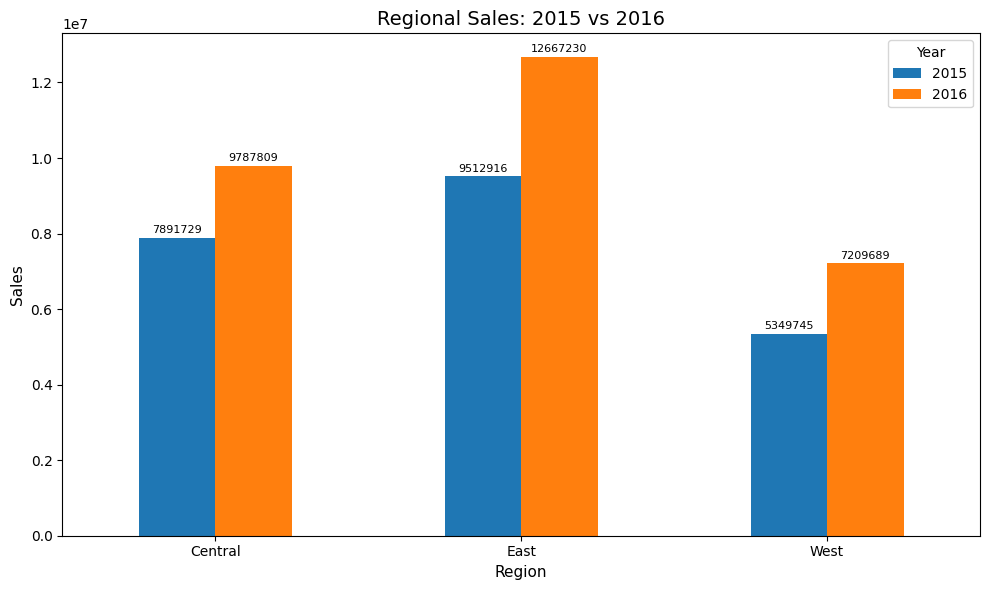

In [4]:
# Reshape wide -> long using stack()
region_sales_long = (
    region_sales
    .stack()
    .reset_index()
    .rename(columns={"level_1": "Year", 0: "Sales"})
)

region_sales_long["Year"] = region_sales_long["Year"].str.replace("Sales", "")

display(region_sales_long)

# Bar chart
pivot_region = region_sales_long.pivot(index="Region", columns="Year", values="Sales")
ax = pivot_region[["2015", "2016"]].plot(kind="bar", figsize=(10, 6))

ax.set_title("Regional Sales: 2015 vs 2016")
ax.set_xlabel("Region")
ax.set_ylabel("Sales")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Year")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2, fontsize=8)

plt.tight_layout()
plt.show()


### Q1 observation

Sales increased from 2015 to 2016 in all three regions: **Central, East and West**. The East region has the highest sales in 2016.


# Q2. Contribution to 2016 Sales by Region

The contribution of each Region to total 2016 sales is represented with a pie chart.


2016 sales by region:


Region
East       1.266723e+07
Central    9.787809e+06
West       7.209689e+06
Name: Sales2016, dtype: float64

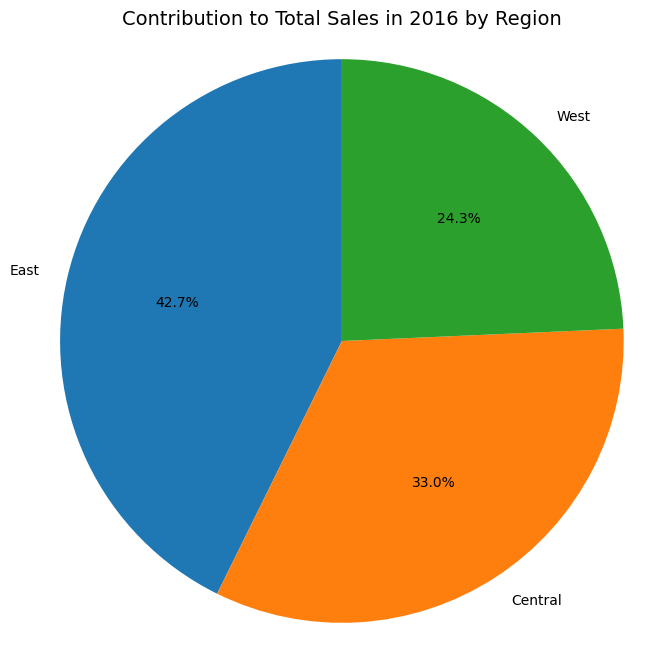

In [5]:
sales_2016_region = sales.groupby("Region")["Sales2016"].sum().sort_values(ascending=False)

print("2016 sales by region:")
display(sales_2016_region)

plt.figure(figsize=(8, 8))
plt.pie(
    sales_2016_region.values,
    labels=sales_2016_region.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Contribution to Total Sales in 2016 by Region")
plt.axis("equal")
plt.show()


# Q3. Compare Sales for 2015 and 2016 by Region and Tier

First aggregate by both `Region` and `Tier`. Then use `unstack()` to reshape the grouped result into a Region × Tier structure.


In [6]:
region_tier_sales = (
    sales.groupby(["Region", "Tier"])[["Sales2015", "Sales2016"]]
         .sum()
)

display(region_tier_sales)


Sales2015     Sales2016
Region  Tier                            
Central High  4.798698e+06  6.026043e+06
        Low   9.434397e+05  1.132833e+06
        Med   2.068226e+06  2.632181e+06
        Out   8.136489e+04 -3.248530e+03
East    High  6.102946e+06  7.817151e+06
        Low   9.016658e+05  1.144930e+06
        Med   2.470998e+06  3.705150e+06
        Out   3.730655e+04  0.000000e+00
West    High  2.944789e+06  3.768038e+06
        Low   6.710644e+05  1.099502e+06
        Med   1.718476e+06  2.342149e+06
        Out   1.541508e+04  0.000000e+00

In [7]:
# Use unstack() to create a Region x Tier structure
sales_2015_rt = region_tier_sales["Sales2015"].unstack(fill_value=0)
sales_2016_rt = region_tier_sales["Sales2016"].unstack(fill_value=0)

print("2015 Sales — Region x Tier")
display(sales_2015_rt)

print("2016 Sales — Region x Tier")
display(sales_2016_rt)


2015 Sales — Region x Tier


Tier,High,Low,Med,Out
Region,,,,
Central,4798698.43,943439.67,2.068226e+06,81364.89
East,6102946.12,901665.80,2.470998e+06,37306.55
West,2944789.26,671064.38,1.718476e+06,15415.08


2016 Sales — Region x Tier


Tier,High,Low,Med,Out
Region,,,,
Central,6026042.94,1132832.85,2.632181e+06,-3248.53
East,7817151.10,1144929.59,3.705150e+06,0.00
West,3768038.35,1099502.18,2.342149e+06,0.00


,Region,Tier,Year,Sales
0,Central,High,2015,4.798698e+06
1,Central,High,2016,6.026043e+06
2,Central,Low,2015,9.434397e+05
3,Central,Low,2016,1.132833e+06
4,Central,Med,2015,2.068226e+06


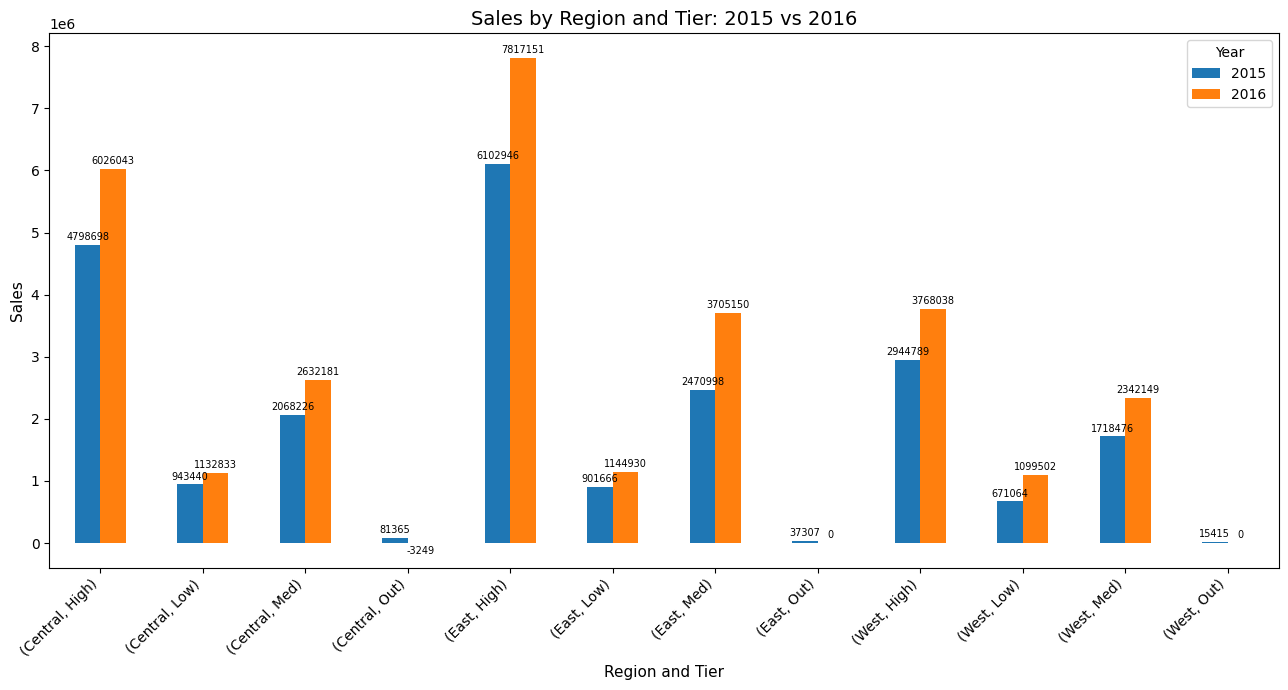

In [8]:
# Prepare long-form data for plotting
region_tier_long = (
    region_tier_sales
    .stack()
    .reset_index()
    .rename(columns={"level_2": "Year", 0: "Sales"})
)

region_tier_long["Year"] = region_tier_long["Year"].str.replace("Sales", "")

display(region_tier_long.head())

# Grouped bar chart
plot_q3 = region_tier_long.pivot_table(
    index=["Region", "Tier"],
    columns="Year",
    values="Sales"
)

ax = plot_q3[["2015", "2016"]].plot(
    kind="bar",
    figsize=(13, 7)
)

ax.set_title("Sales by Region and Tier: 2015 vs 2016")
ax.set_xlabel("Region and Tier")
ax.set_ylabel("Sales")
ax.legend(title="Year")
plt.xticks(rotation=45, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2, fontsize=7)

plt.tight_layout()
plt.show()


# Q4. East Region — State with a Decline in Sales

We filter the data to the East region, aggregate sales by State, and compare 2015 with 2016.


In [9]:
east_state_sales = (
    sales[sales["Region"] == "East"]
    .groupby("State")[["Sales2015", "Sales2016"]]
    .sum()
)

east_state_sales["Change"] = east_state_sales["Sales2016"] - east_state_sales["Sales2015"]
east_state_sales["Change_%"] = (
    east_state_sales["Change"] / east_state_sales["Sales2015"] * 100
)

display(east_state_sales.sort_values("Change"))

declining_east = east_state_sales[east_state_sales["Change"] < 0].sort_values("Change")
print("State(s) with a decline in the East region:")
display(declining_east)


,Sales2015,Sales2016,Change,Change_%
State,,,,
NY,1725415.065,1703135.80,-22279.265,-1.291241
RI,156311.800,162454.65,6142.850,3.929870
NH,136419.380,144717.51,8298.130,6.082809
TN,49677.000,70109.41,20432.410,41.130523
DC,216723.950,257421.69,40697.740,18.778608
ME,77425.640,183673.05,106247.410,137.225098
PA,785092.755,894319.49,109226.735,13.912590
CT,197202.790,323502.31,126299.520,64.045504
SC,247811.780,463414.12,215602.340,87.002458


State(s) with a decline in the East region:


,Sales2015,Sales2016,Change,Change_%
State,,,,
NY,1725415.065,1703135.8,-22279.265,-1.291241


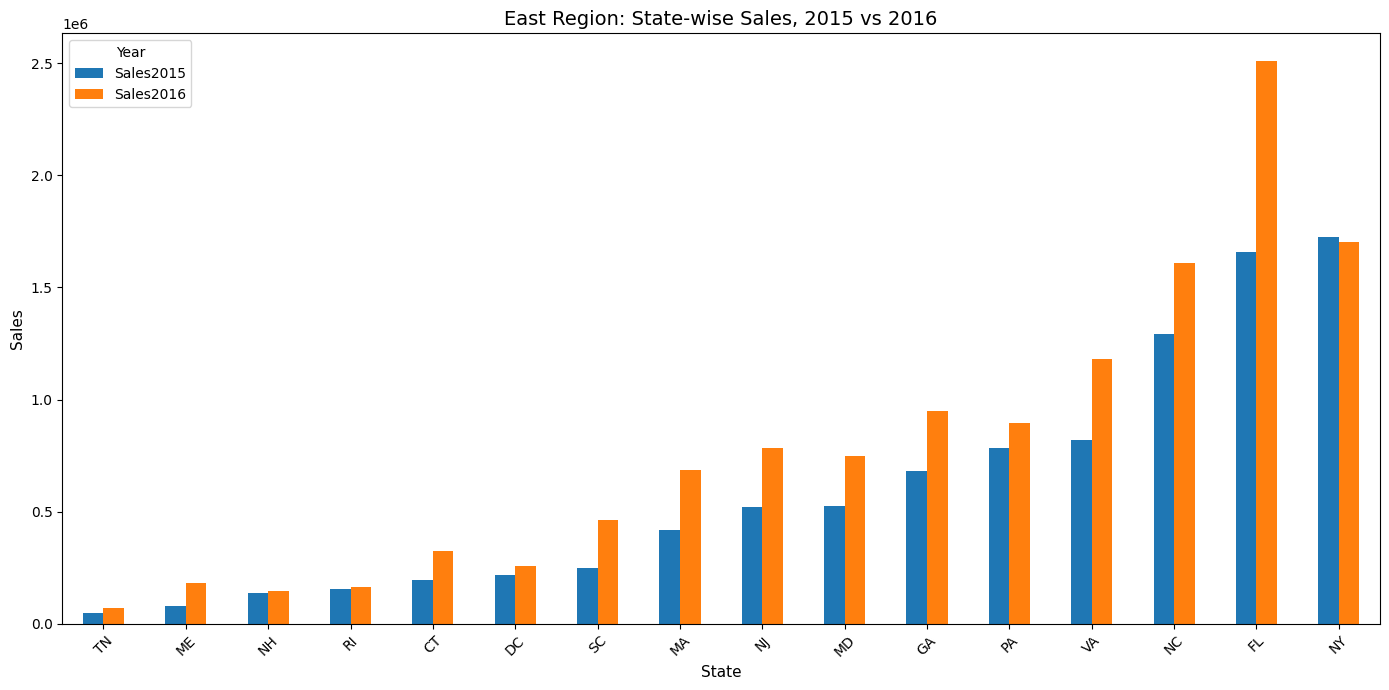

Answer: NY


In [10]:
# Visualization for Q4
q4_plot = east_state_sales[["Sales2015", "Sales2016"]].sort_values("Sales2015")

ax = q4_plot.plot(kind="bar", figsize=(14, 7))
ax.set_title("East Region: State-wise Sales, 2015 vs 2016")
ax.set_xlabel("State")
ax.set_ylabel("Sales")
ax.legend(title="Year")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("Answer:", ", ".join(declining_east.index))


# Q5. High Tier — Division with a Decline in Units Sold

We restrict the data to `Tier == "High"`, aggregate `Units2015` and `Units2016` by Division, and calculate the change.

**Note:** The supplied dataset determines the answer. If no Division has a negative change after aggregation, the correct data-driven answer is that **no Division declined overall**.


In [11]:
high_division_units = (
    sales[sales["Tier"] == "High"]
    .groupby("Division")[["Units2015", "Units2016"]]
    .sum()
)

high_division_units["Change"] = (
    high_division_units["Units2016"] - high_division_units["Units2015"]
)

high_division_units["Change_%"] = (
    high_division_units["Change"] / high_division_units["Units2015"] * 100
)

display(high_division_units.sort_values("Change"))


,Units2015,Units2016,Change,Change_%
Division,,,,
NORDIC,210.1675,225.8334,15.6659,7.454007
WOLVERINE,122.0002,143.0000,20.9998,17.212923
REVOLUTION,205.8335,226.8334,20.9999,10.202372
DIAMONDBACK,153.3334,176.6667,23.3333,15.217363
NORTHWEST,135.5008,163.6669,28.1661,20.786667
KINETIC,214.3334,244.5001,30.1667,14.074661
GRIDIRON,213.6673,246.1675,32.5002,15.210657
EMPIRE,414.3332,449.3332,35.0000,8.447308
RIPTIDE,147.5002,183.8336,36.3334,24.632780


In [12]:
declining_high_divisions = high_division_units[
    high_division_units["Change"] < 0
].sort_values("Change")

if declining_high_divisions.empty:
    print("Answer: No High-tier Division registered an overall decline in units sold in 2016.")
else:
    print("Division(s) with a decline:")
    display(declining_high_divisions)


Answer: No High-tier Division registered an overall decline in units sold in 2016.


# Q6. Create the `Qtr` Column

The case study defines:

- Jan–Mar → Q1
- Apr–Jun → Q2
- Jul–Sep → Q3
- Oct–Dec → Q4

Here `numpy.select()` is used as a suitable NumPy-based utility for creating the new column.


In [13]:
# Create Quarter column using NumPy
conditions = [
    sales["Month"].isin(["Jan", "Feb", "Mar"]),
    sales["Month"].isin(["Apr", "May", "Jun"]),
    sales["Month"].isin(["Jul", "Aug", "Sep"]),
    sales["Month"].isin(["Oct", "Nov", "Dec"])
]

choices = ["Q1", "Q2", "Q3", "Q4"]

sales["Qtr"] = np.select(conditions, choices, default="")

# Keep the requested chronological order
sales["Qtr"] = pd.Categorical(
    sales["Qtr"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

display(sales[["Month", "Qtr"]].drop_duplicates().sort_values("Qtr"))


,Month,Qtr
3,Mar,Q1
6,Feb,Q1
31,Jan,Q1
2,Jun,Q2
18,Apr,Q2
22,May,Q2
0,Aug,Q3
4,Sep,Q3
5,Jul,Q3
1,Oct,Q4


# Q7. Compare Quarter-wise Sales in 2015 and 2016


In [14]:
quarter_sales = (
    sales.groupby("Qtr", observed=True)[["Sales2015", "Sales2016"]]
         .sum()
         .reindex(["Q1", "Q2", "Q3", "Q4"])
)

display(quarter_sales)


,Sales2015,Sales2016
Qtr,,
Q1,5.485800e+06,6.997953e+06
Q2,5.390862e+06,7.237361e+06
Q3,6.164094e+06,7.861546e+06
Q4,5.713634e+06,7.567868e+06


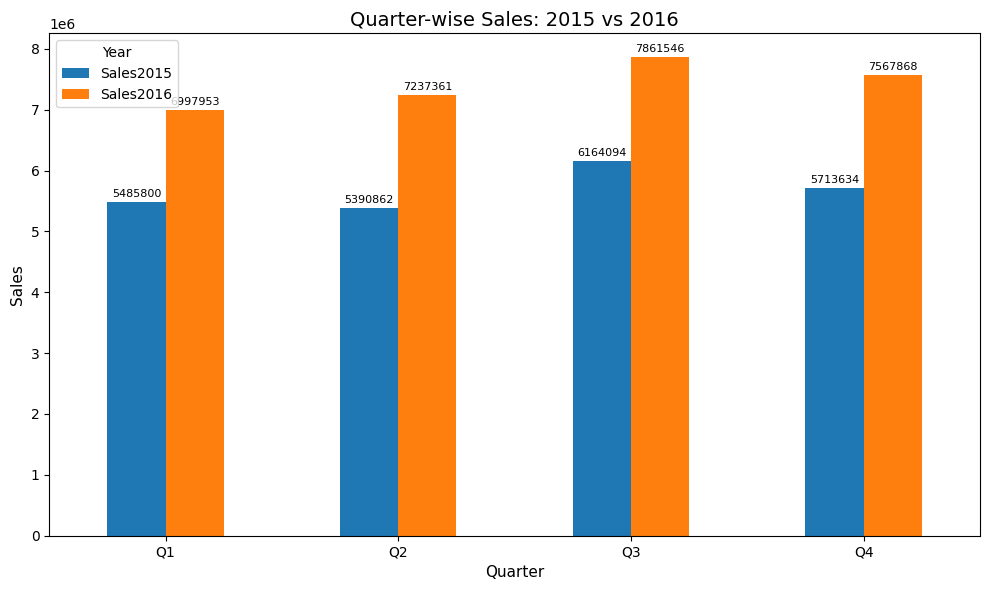

In [15]:
ax = quarter_sales.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("Quarter-wise Sales: 2015 vs 2016")
ax.set_xlabel("Quarter")
ax.set_ylabel("Sales")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Year")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2, fontsize=8)

plt.tight_layout()
plt.show()


# Q8. Composition of 2016 Quarter-wise Sales by Tier

The case study asks for **four pie charts**, one for each quarter, showing the contribution of the four Tiers (`High`, `Med`, `Low`, `Out`) to sales.

Each quarter is plotted separately below.


Q1 Tier-wise 2016 sales:


Tier
High    3867718.595
Med     2181401.879
Low      948832.770
Out           0.000
Name: Sales2016, dtype: float64

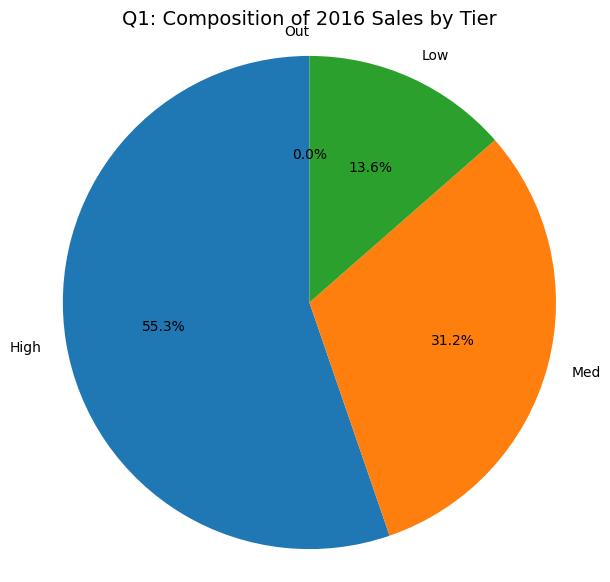

In [16]:
# Q1 — Tier-wise composition of 2016 sales
Q1_tier_sales = (
    sales[sales["Qtr"] == "Q1"]
    .groupby("Tier")["Sales2016"]
    .sum()
    .reindex(["High", "Med", "Low", "Out"])
    .dropna()
)

print("Q1 Tier-wise 2016 sales:")
display(Q1_tier_sales)

plt.figure(figsize=(7, 7))
plt.pie(
    Q1_tier_sales.values,
    labels=Q1_tier_sales.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Q1: Composition of 2016 Sales by Tier")
plt.axis("equal")
plt.show()


Q2 Tier-wise 2016 sales:


Tier
High    4.130953e+06
Med     2.215814e+06
Low     8.905948e+05
Out     0.000000e+00
Name: Sales2016, dtype: float64

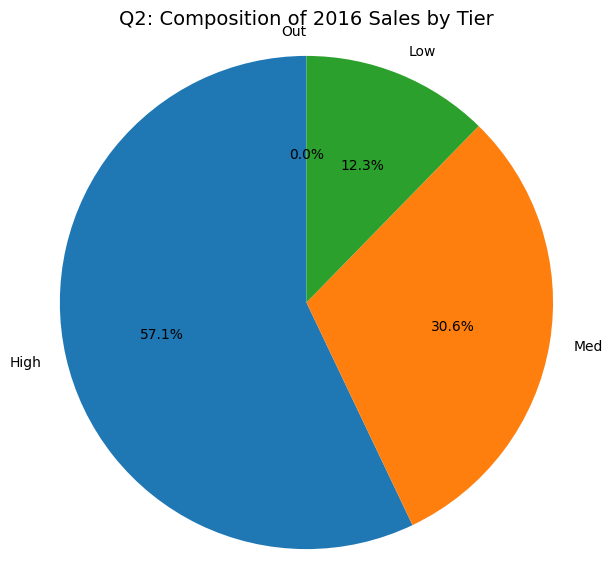

In [17]:
# Q2 — Tier-wise composition of 2016 sales
Q2_tier_sales = (
    sales[sales["Qtr"] == "Q2"]
    .groupby("Tier")["Sales2016"]
    .sum()
    .reindex(["High", "Med", "Low", "Out"])
    .dropna()
)

print("Q2 Tier-wise 2016 sales:")
display(Q2_tier_sales)

plt.figure(figsize=(7, 7))
plt.pie(
    Q2_tier_sales.values,
    labels=Q2_tier_sales.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Q2: Composition of 2016 Sales by Tier")
plt.axis("equal")
plt.show()


Q3 Tier-wise 2016 sales:


Tier
High    4.872559e+06
Med     2.197058e+06
Low     7.951777e+05
Out    -3.248530e+03
Name: Sales2016, dtype: float64

Note: negative net sales are excluded from the Q3 pie chart because pie slices cannot be negative.


Tier
Out   -3248.53
Name: Negative sales excluded from pie, dtype: float64

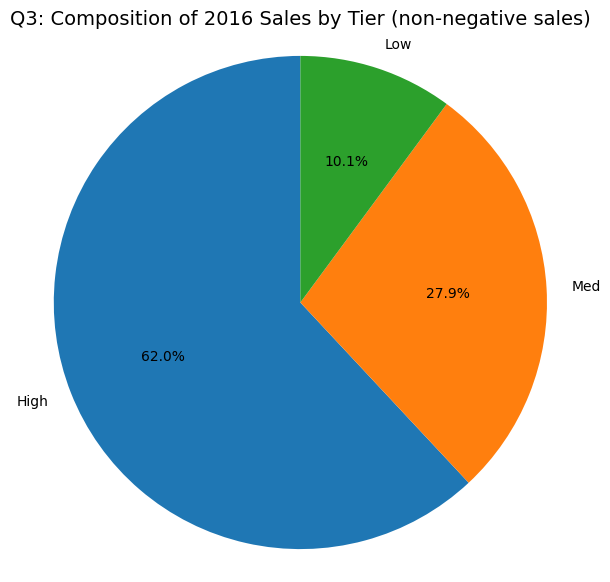

In [18]:
# Q3 — Tier-wise composition of 2016 sales
Q3_tier_sales = (
    sales[sales["Qtr"] == "Q3"]
    .groupby("Tier")["Sales2016"]
    .sum()
    .reindex(["High", "Med", "Low", "Out"])
)

print("Q3 Tier-wise 2016 sales:")
display(Q3_tier_sales)

# A pie chart cannot display a negative slice. The supplied data contains
# negative net 2016 sales for the Out tier in Q3, so that slice is excluded
# from the pie and reported separately.
Q3_nonnegative = Q3_tier_sales[Q3_tier_sales >= 0].dropna()
Q3_negative = Q3_tier_sales[Q3_tier_sales < 0].dropna()

if not Q3_negative.empty:
    print("Note: negative net sales are excluded from the Q3 pie chart because pie slices cannot be negative.")
    display(Q3_negative.rename("Negative sales excluded from pie"))

plt.figure(figsize=(7, 7))
plt.pie(
    Q3_nonnegative.values,
    labels=Q3_nonnegative.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Q3: Composition of 2016 Sales by Tier (non-negative sales)")
plt.axis("equal")
plt.show()


Q4 Tier-wise 2016 sales:


Tier
High    4.740002e+06
Med     2.085207e+06
Low     7.426594e+05
Out     0.000000e+00
Name: Sales2016, dtype: float64

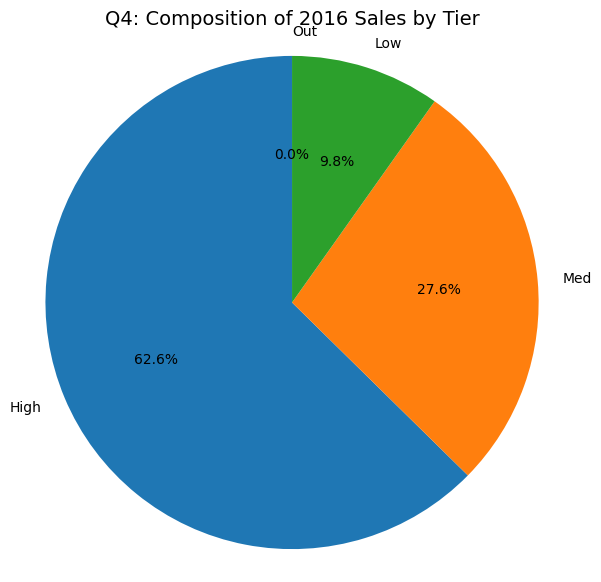

In [19]:
# Q4 — Tier-wise composition of 2016 sales
Q4_tier_sales = (
    sales[sales["Qtr"] == "Q4"]
    .groupby("Tier")["Sales2016"]
    .sum()
    .reindex(["High", "Med", "Low", "Out"])
    .dropna()
)

print("Q4 Tier-wise 2016 sales:")
display(Q4_tier_sales)

plt.figure(figsize=(7, 7))
plt.pie(
    Q4_tier_sales.values,
    labels=Q4_tier_sales.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Q4: Composition of 2016 Sales by Tier")
plt.axis("equal")
plt.show()


# Final Answers / Findings

### 1. Regional sales
2016 sales are higher than 2015 sales in **Central, East and West**. East has the highest 2016 sales.

### 2. 2016 regional contribution
The pie chart shows the percentage contribution of Central, East and West to total 2016 sales.

### 3. Region + Tier
The grouped aggregation and chart compare 2015 and 2016 sales across every Region–Tier combination.

### 4. East region decline
**NY** is the East-region state with an overall decline in sales in 2016 compared with 2015.

### 5. High-tier division decline
For the supplied dataset, **no High-tier Division has an overall decline in units sold** after aggregating 2015 and 2016.

### 6. Quarter column
`Qtr` has been created using the requested Jan–Mar / Apr–Jun / Jul–Sep / Oct–Dec mapping.

### 7. Quarter-wise sales
2016 sales are higher than 2015 sales in **Q1, Q2, Q3 and Q4**.

### 8. Quarter-wise tier composition
Four separate pie charts show the Tier composition of 2016 sales for Q1, Q2, Q3 and Q4. The supplied data contains a negative net `Sales2016` value for the **Out** tier in Q3; because a pie chart cannot contain a negative slice, that value is reported separately and excluded from the Q3 pie visualization.

---

**Dataset used:** `SalesData.csv`  
**Tools:** Pandas, NumPy, Matplotlib  
**Notebook:** Ready to open and run in Jupyter Notebook / JupyterLab.
